<a href="https://colab.research.google.com/github/ZhannaPavlova/business_analytics_visualizations/blob/main/pharma_qbd_unit_economics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

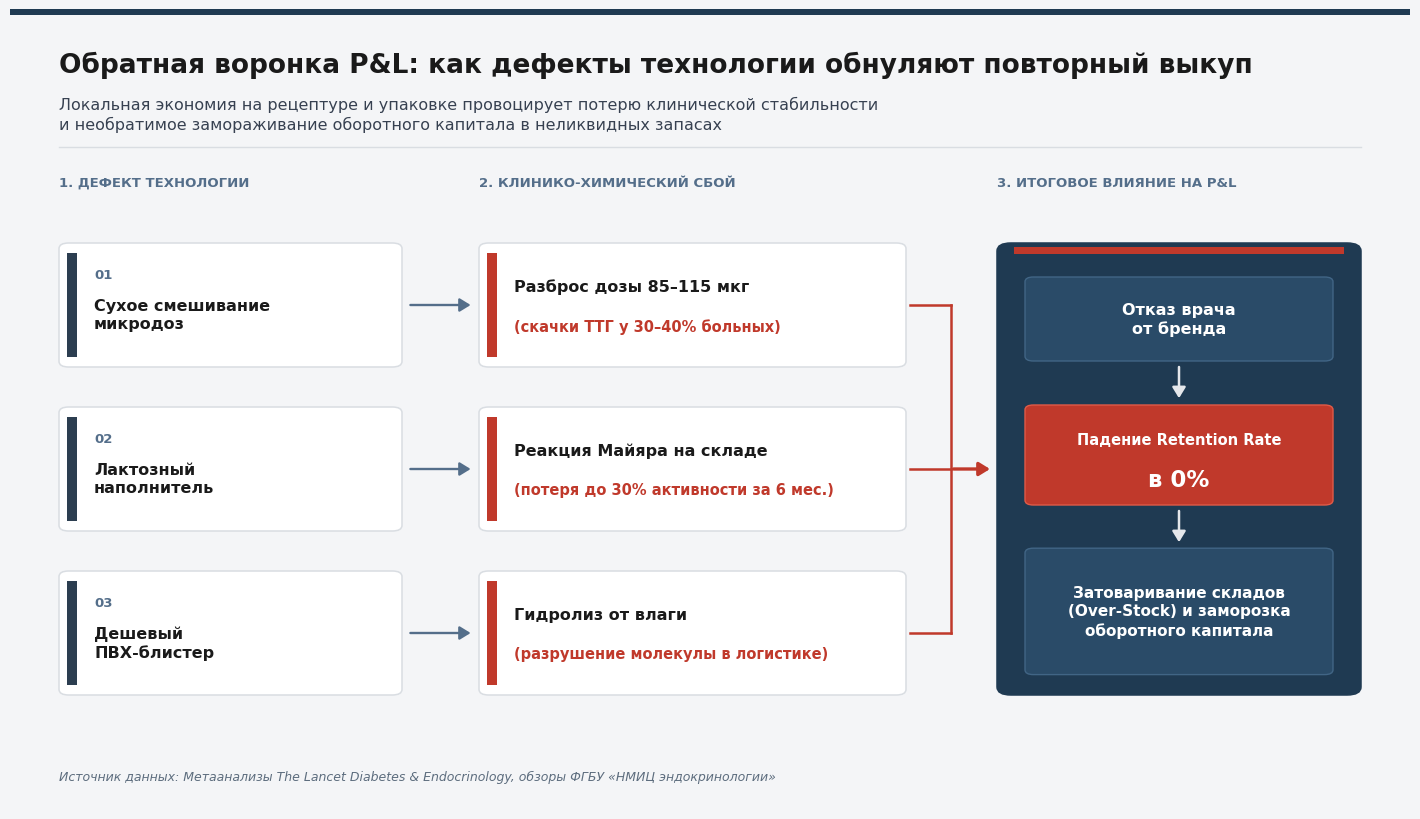

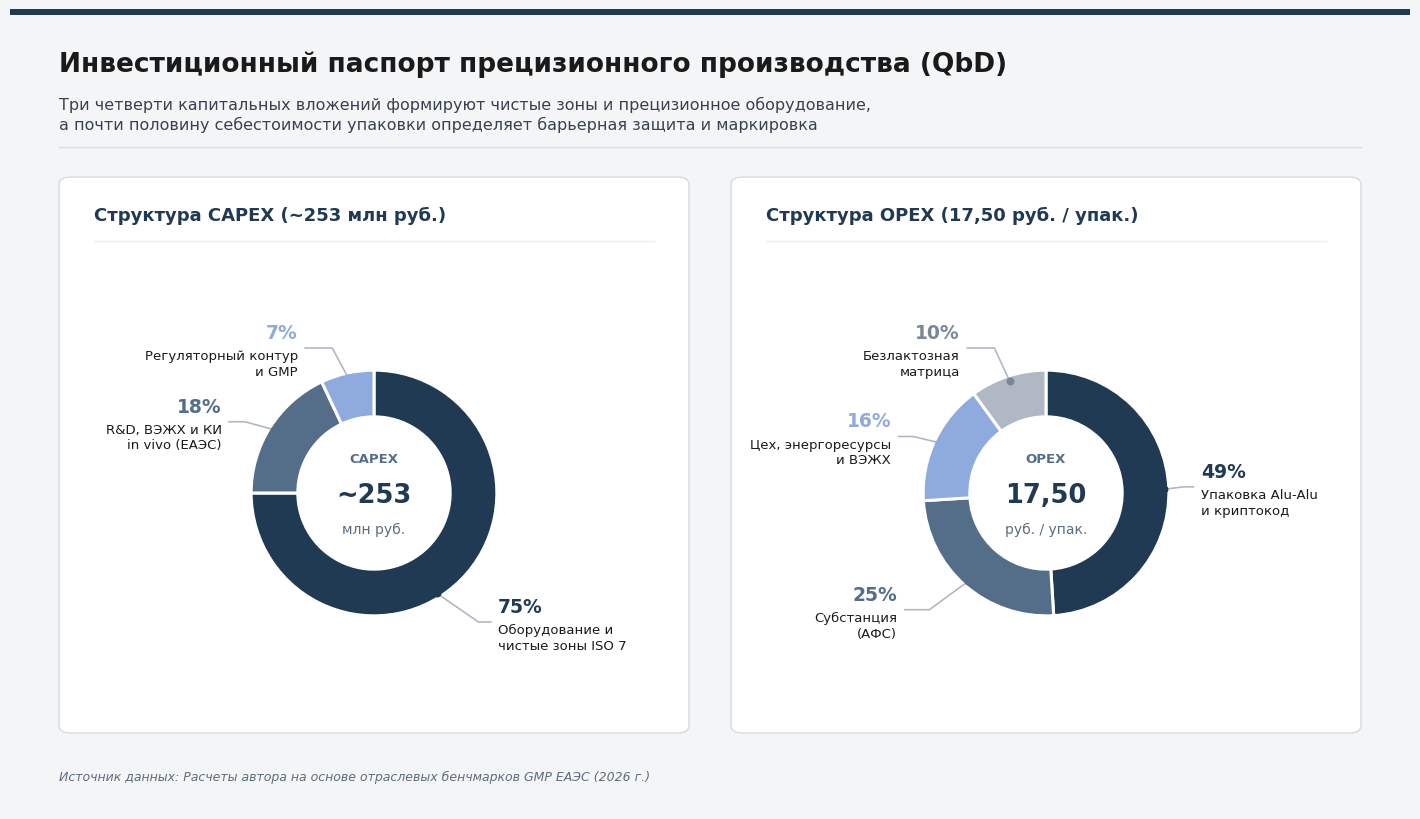

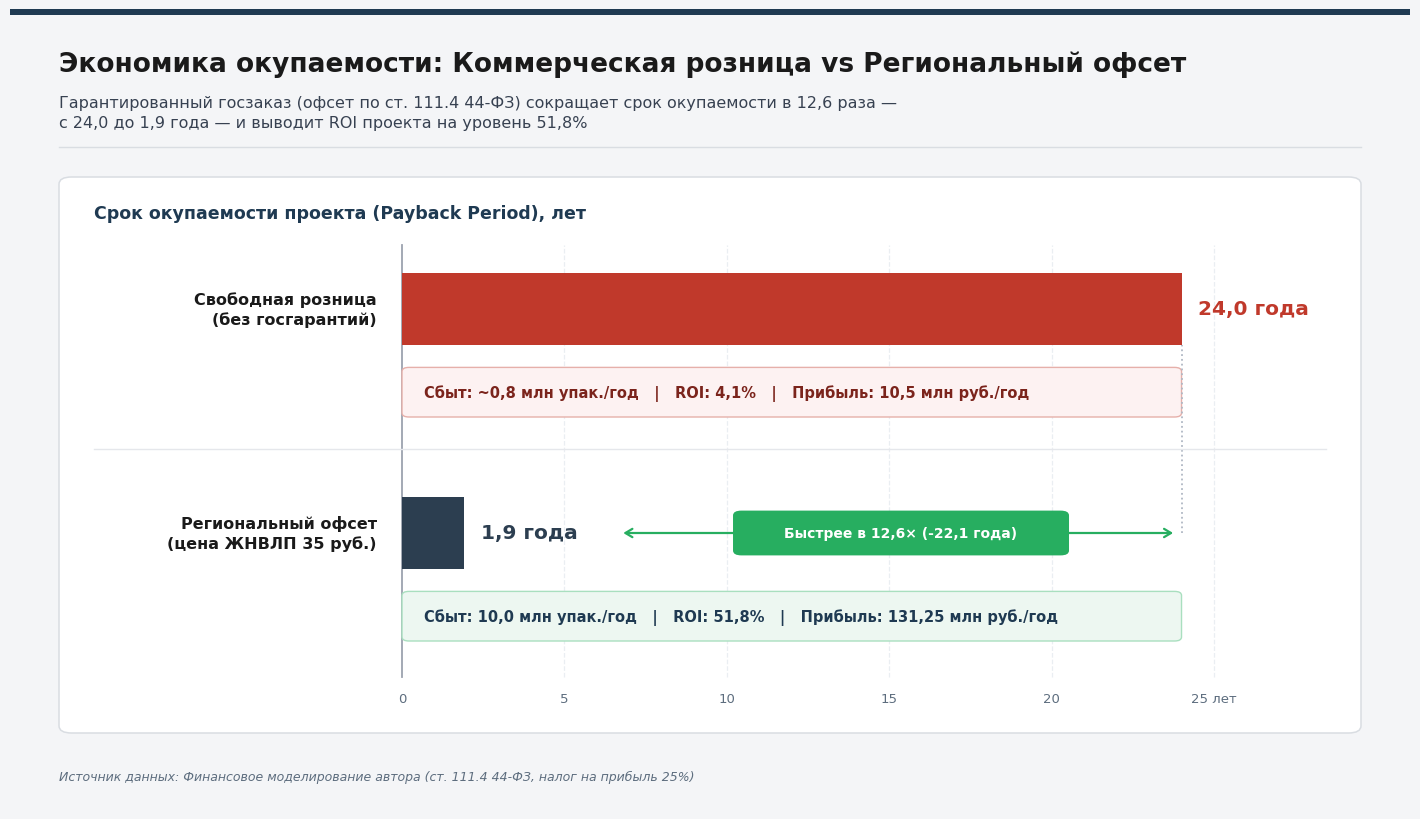

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

[None, None, None]

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch, Rectangle
from google.colab import files

# Глобальные настройки стиля McKinsey
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['axes.unicode_minus'] = False

BG_COLOR = '#F4F5F7'
CARD_BG = '#FFFFFF'
CARD_BORDER = '#D9DDE2'
NAVY_DARK = '#1F3A52'
NAVY = '#2C3E50'
STEEL_BLUE = '#546E8A'
LIGHT_BLUE = '#8FAADC'
SOFT_GRAY = '#B0B8C4'
RISK_RED = '#C0392B'
POS_GREEN = '#27AE60'
TEXT_DARK = '#1A1A1A'
TEXT_MUTED = '#5D6D7E'


def setup_slide(figsize=(14, 8)):
    fig = plt.figure(figsize=figsize, facecolor=BG_COLOR)
    ax = fig.add_axes([0, 0, 1, 1], facecolor=BG_COLOR)
    ax.set_xlim(0, 100)
    ax.set_ylim(0, 100)
    ax.axis('off')
    # Тонкая верхняя акцентная линия слайда
    ax.add_patch(Rectangle((0, 99.2), 100, 0.8, facecolor=NAVY_DARK, edgecolor='none'))
    return fig, ax


def add_header_footer(ax, title, action_title, source_text):
    ax.text(
        3.5, 94.8, title,
        fontsize=19, fontweight='bold', color=TEXT_DARK,
        ha='left', va='top'
    )
    ax.text(
        3.5, 89.2, action_title,
        fontsize=11.5, color='#374151',
        ha='left', va='top', linespacing=1.35
    )
    ax.plot([3.5, 96.5], [82.8, 82.8], color=CARD_BORDER, linewidth=1.0)
    ax.text(
        3.5, 3.2, source_text,
        fontsize=9, style='italic', color=TEXT_MUTED,
        ha='left', va='bottom'
    )


def add_card(ax, x, y, w, h, facecolor=CARD_BG, edgecolor=CARD_BORDER, lw=1.1, r=0.8):
    card = FancyBboxPatch(
        (x, y), w, h,
        boxstyle=f'round,pad=0,rounding_size={r}',
        facecolor=facecolor, edgecolor=edgecolor, linewidth=lw, zorder=2
    )
    ax.add_patch(card)
    return card


def add_arrow(ax, x1, y1, x2, y2, color=STEEL_BLUE, lw=1.8, rad=0.0):
    arrow = FancyArrowPatch(
        (x1, y1), (x2, y2),
        arrowstyle='-|>,head_length=6.5,head_width=4.0',
        color=color, linewidth=lw,
        connectionstyle=f'arc3,rad={rad}',
        zorder=4
    )
    ax.add_patch(arrow)


# ==============================================================================
# ГРАФИК 1: Обратная воронка P&L
# ==============================================================================
def create_chart_1():
    fig, ax = setup_slide(figsize=(14, 8))
    add_header_footer(
        ax,
        title='Обратная воронка P&L: как дефекты технологии обнуляют повторный выкуп',
        action_title=(
            'Локальная экономия на рецептуре и упаковке провоцирует потерю клинической стабильности\n'
            'и необратимое замораживание оборотного капитала в неликвидных запасах'
        ),
        source_text='Источник данных: Метаанализы The Lancet Diabetes & Endocrinology, обзоры ФГБУ «НМИЦ эндокринологии»'
    )

    # Заголовки этапов каскада
    stage_headers = [
        (3.5, '1. ДЕФЕКТ ТЕХНОЛОГИИ'),
        (33.5, '2. КЛИНИКО-ХИМИЧЕСКИЙ СБОЙ'),
        (70.5, '3. ИТОГОВОЕ ВЛИЯНИЕ НА P&L')
    ]
    for sx, stext in stage_headers:
        ax.text(sx, 77.5, stext, fontsize=9.5, fontweight='bold', color=STEEL_BLUE, ha='left', va='bottom')

    branches = [
        {
            'y_center': 63.0,
            'num': '01',
            'left_title': 'Сухое смешивание\nмикродоз',
            'mid_title': 'Разброс дозы 85–115 мкг',
            'mid_sub': '(скачки ТТГ у 30–40% больных)'
        },
        {
            'y_center': 42.5,
            'num': '02',
            'left_title': 'Лактозный\nнаполнитель',
            'mid_title': 'Реакция Майяра на складе',
            'mid_sub': '(потеря до 30% активности за 6 мес.)'
        },
        {
            'y_center': 22.0,
            'num': '03',
            'left_title': 'Дешевый\nПВХ-блистер',
            'mid_title': 'Гидролиз от влаги',
            'mid_sub': '(разрушение молекулы в логистике)'
        }
    ]

    card_h = 15.5
    for b in branches:
        yc = b['y_center']
        y0 = yc - card_h / 2.0

        # Левая карточка (технологический дефект)
        add_card(ax, 3.5, y0, 24.5, card_h, facecolor=CARD_BG, edgecolor=CARD_BORDER, r=0.7)
        ax.add_patch(Rectangle((4.1, y0 + 1.2), 0.7, card_h - 2.4, facecolor=NAVY, edgecolor='none', zorder=3))
        ax.text(6.0, yc + 3.8, b['num'], fontsize=9.5, fontweight='bold', color=STEEL_BLUE, ha='left', va='center', zorder=4)
        ax.text(6.0, yc - 1.2, b['left_title'], fontsize=11.5, fontweight='bold', color=TEXT_DARK, ha='left', va='center', linespacing=1.25, zorder=4)

        # Стрелка к последствию
        add_arrow(ax, 28.4, yc, 33.1, yc, color=STEEL_BLUE, lw=1.7)

        # Средняя карточка (клиническое/химическое последствие)
        add_card(ax, 33.5, y0, 30.5, card_h, facecolor=CARD_BG, edgecolor=CARD_BORDER, r=0.7)
        ax.add_patch(Rectangle((34.1, y0 + 1.2), 0.7, card_h - 2.4, facecolor=RISK_RED, edgecolor='none', zorder=3))
        ax.text(36.0, yc + 2.3, b['mid_title'], fontsize=11.5, fontweight='bold', color=TEXT_DARK, ha='left', va='center', zorder=4)
        ax.text(36.0, yc - 2.6, b['mid_sub'], fontsize=10.5, fontweight='bold', color=RISK_RED, ha='left', va='center', zorder=4)

        # Коллекторная линия к правому блоку
        ax.plot([64.3, 67.2], [yc, yc], color=RISK_RED, linewidth=1.8, zorder=3)

    # Вертикальный коллектор и итоговая стрелка
    ax.plot([67.2, 67.2], [22.0, 63.0], color=RISK_RED, linewidth=1.8, zorder=3)
    add_arrow(ax, 67.2, 42.5, 70.2, 42.5, color=RISK_RED, lw=2.4)

    # Правый акцентный итоговый блок P&L
    rx, ry, rw, rh = 70.5, 14.25, 26.0, 56.5
    add_card(ax, rx, ry, rw, rh, facecolor=NAVY_DARK, edgecolor=NAVY_DARK, r=1.0)
    # Красная акцентная верхняя полоса внутри итогового блока
    ax.add_patch(Rectangle((rx + 1.2, ry + rh - 1.4), rw - 2.4, 0.9, facecolor=RISK_RED, edgecolor='none', zorder=3))

    # Шаг 1 в итоговом блоке
    add_card(ax, rx + 2.0, 56.0, rw - 4.0, 10.5, facecolor='#2A4B68', edgecolor='#416585', lw=1.0, r=0.6)
    ax.text(rx + rw / 2, 61.25, 'Отказ врача\nот бренда', fontsize=11.5, fontweight='bold', color='#FFFFFF', ha='center', va='center', linespacing=1.25, zorder=4)

    add_arrow(ax, rx + rw / 2, 55.6, rx + rw / 2, 51.0, color='#E5E7EB', lw=1.8)

    # Шаг 2 в итоговом блоке (акцент на 0%)
    add_card(ax, rx + 2.0, 38.0, rw - 4.0, 12.5, facecolor=RISK_RED, edgecolor='#E05A47', lw=1.0, r=0.6)
    ax.text(rx + rw / 2, 46.2, 'Падение Retention Rate', fontsize=10.5, fontweight='bold', color='#FFFFFF', ha='center', va='center', zorder=4)
    ax.text(rx + rw / 2, 41.2, 'в 0%', fontsize=16.5, fontweight='bold', color='#FFFFFF', ha='center', va='center', zorder=4)

    add_arrow(ax, rx + rw / 2, 37.6, rx + rw / 2, 33.0, color='#E5E7EB', lw=1.8)

    # Шаг 3 в итоговом блоке
    add_card(ax, rx + 2.0, 16.8, rw - 4.0, 15.8, facecolor='#2A4B68', edgecolor='#416585', lw=1.0, r=0.6)
    ax.text(
        rx + rw / 2, 24.7,
        'Затоваривание складов\n(Over-Stock) и заморозка\nоборотного капитала',
        fontsize=11.0, fontweight='bold', color='#FFFFFF',
        ha='center', va='center', linespacing=1.3, zorder=4
    )

    fig.savefig('chart1_pnl_funnel.png', dpi=300, facecolor=BG_COLOR)
    plt.show()


# ==============================================================================
# ГРАФИК 2: Инвестиционный паспорт прецизионного производства (QbD)
# ==============================================================================
def draw_donut_with_callouts(fig, ax_rect, data, colors, callout_specs, center_top, center_val, center_unit):
    ax_d = fig.add_axes(ax_rect, facecolor='none', zorder=4)
    ax_d.pie(
        data,
        startangle=90,
        counterclock=False,
        colors=colors,
        wedgeprops=dict(width=0.38, edgecolor='#FFFFFF', linewidth=2.2)
    )
    ax_d.set_aspect('equal')
    ax_d.set_xlim(-2.45, 2.45)
    ax_d.set_ylim(-1.55, 1.55)
    ax_d.axis('off')

    # Текст в центре кольца
    ax_d.text(0, 0.28, center_top, fontsize=9.5, fontweight='bold', color=STEEL_BLUE, ha='center', va='center')
    ax_d.text(0, -0.02, center_val, fontsize=18.5, fontweight='bold', color=NAVY_DARK, ha='center', va='center')
    ax_d.text(0, -0.29, center_unit, fontsize=10.0, color=TEXT_MUTED, ha='center', va='center')

    # Выноски к сегментам
    for spec in callout_specs:
        angle_rad = np.deg2rad(spec['angle'])
        x0, y0 = 0.96 * np.cos(angle_rad), 0.96 * np.sin(angle_rad)
        xm, ym = spec['elbow']
        xt, yt = spec['text_pos']
        ha = spec['ha']

        ax_d.plot([x0, xm, xt], [y0, ym, yt], color=SOFT_GRAY, linewidth=1.2, zorder=3)
        ax_d.scatter([x0], [y0], color=spec['dot_color'], s=22, zorder=5)

        tx = xt + (0.06 if ha == 'left' else -0.06)
        ax_d.text(
            tx, yt + 0.05, spec['pct'],
            fontsize=13.5, fontweight='bold', color=spec['dot_color'],
            ha=ha, va='bottom'
        )
        ax_d.text(
            tx, yt - 0.01, spec['label'],
            fontsize=9.5, color=TEXT_DARK,
            ha=ha, va='top', linespacing=1.25
        )


def create_chart_2():
    fig, ax = setup_slide(figsize=(14, 8))
    add_header_footer(
        ax,
        title='Инвестиционный паспорт прецизионного производства (QbD)',
        action_title=(
            'Три четверти капитальных вложений формируют чистые зоны и прецизионное оборудование,\n'
            'а почти половину себестоимости упаковки определяет барьерная защита и маркировка'
        ),
        source_text='Источник данных: Расчеты автора на основе отраслевых бенчмарков GMP ЕАЭС (2026 г.)'
    )

    # Левая белая карточка: CAPEX
    add_card(ax, 3.5, 9.5, 45.0, 69.5, facecolor=CARD_BG, edgecolor=CARD_BORDER, r=0.9)
    ax.text(6.0, 74.2, 'Структура CAPEX (~253 млн руб.)', fontsize=13, fontweight='bold', color=NAVY_DARK, ha='left', va='center', zorder=4)
    ax.plot([6.0, 46.0], [71.0, 71.0], color='#EAEEF2', linewidth=1.0, zorder=3)

    capex_colors = [NAVY_DARK, STEEL_BLUE, LIGHT_BLUE]
    capex_callouts = [
        {
            'angle': -58.0,
            'elbow': (0.85, -1.05),
            'text_pos': (0.95, -1.05),
            'ha': 'left',
            'dot_color': NAVY_DARK,
            'pct': '75%',
            'label': 'Оборудование и\nчистые зоны ISO 7'
        },
        {
            'angle': 147.6,
            'elbow': (-1.05, 0.58),
            'text_pos': (-1.18, 0.58),
            'ha': 'right',
            'dot_color': STEEL_BLUE,
            'pct': '18%',
            'label': 'R&D, ВЭЖХ и КИ\nin vivo (ЕАЭС)'
        },
        {
            'angle': 102.6,
            'elbow': (-0.34, 1.18),
            'text_pos': (-0.56, 1.18),
            'ha': 'right',
            'dot_color': LIGHT_BLUE,
            'pct': '7%',
            'label': 'Регуляторный контур\nи GMP'
        }
    ]
    draw_donut_with_callouts(
        fig, [0.045, 0.11, 0.43, 0.57],
        data=[75, 18, 7], colors=capex_colors, callout_specs=capex_callouts,
        center_top='CAPEX', center_val='~253', center_unit='млн руб.'
    )

    # Правая белая карточка: OPEX
    add_card(ax, 51.5, 9.5, 45.0, 69.5, facecolor=CARD_BG, edgecolor=CARD_BORDER, r=0.9)
    ax.text(54.0, 74.2, 'Структура OPEX (17,50 руб. / упак.)', fontsize=13, fontweight='bold', color=NAVY_DARK, ha='left', va='center', zorder=4)
    ax.plot([54.0, 94.0], [71.0, 71.0], color='#EAEEF2', linewidth=1.0, zorder=3)

    opex_colors = [NAVY_DARK, STEEL_BLUE, LIGHT_BLUE, SOFT_GRAY]
    opex_callouts = [
        {
            'angle': 1.8,
            'elbow': (1.12, 0.05),
            'text_pos': (1.20, 0.05),
            'ha': 'left',
            'dot_color': NAVY_DARK,
            'pct': '49%',
            'label': 'Упаковка Alu-Alu\nи криптокод'
        },
        {
            'angle': -131.4,
            'elbow': (-0.95, -0.95),
            'text_pos': (-1.15, -0.95),
            'ha': 'right',
            'dot_color': STEEL_BLUE,
            'pct': '25%',
            'label': 'Субстанция\n(АФС)'
        },
        {
            'angle': 154.8,
            'elbow': (-1.08, 0.46),
            'text_pos': (-1.20, 0.46),
            'ha': 'right',
            'dot_color': LIGHT_BLUE,
            'pct': '16%',
            'label': 'Цех, энергоресурсы\nи ВЭЖХ'
        },
        {
            'angle': 108.0,
            'elbow': (-0.42, 1.18),
            'text_pos': (-0.64, 1.18),
            'ha': 'right',
            'dot_color': '#7A8699',
            'pct': '10%',
            'label': 'Безлактозная\nматрица'
        }
    ]
    draw_donut_with_callouts(
        fig, [0.525, 0.11, 0.43, 0.57],
        data=[49, 25, 16, 10], colors=opex_colors, callout_specs=opex_callouts,
        center_top='OPEX', center_val='17,50', center_unit='руб. / упак.'
    )

    fig.savefig('chart2_qbd_capex_opex.png', dpi=300, facecolor=BG_COLOR)
    plt.show()


# ==============================================================================
# ГРАФИК 3: Экономика окупаемости: Коммерческая розница vs Региональный офсет
# ==============================================================================
def create_chart_3():
    fig, ax = setup_slide(figsize=(14, 8))
    add_header_footer(
        ax,
        title='Экономика окупаемости: Коммерческая розница vs Региональный офсет',
        action_title=(
            'Гарантированный госзаказ (офсет по ст. 111.4 44-ФЗ) сокращает срок окупаемости в 12,6 раза —\n'
            'с 24,0 до 1,9 года — и выводит ROI проекта на уровень 51,8%'
        ),
        source_text='Источник данных: Финансовое моделирование автора (ст. 111.4 44-ФЗ, налог на прибыль 25%)'
    )

    # Единая белая карточка графика
    add_card(ax, 3.5, 9.5, 93.0, 69.5, facecolor=CARD_BG, edgecolor=CARD_BORDER, r=0.9)
    ax.text(6.0, 74.5, 'Срок окупаемости проекта (Payback Period), лет', fontsize=12.5, fontweight='bold', color=NAVY_DARK, ha='left', va='center', zorder=4)

    # Система координат полос: от 0 до 25 лет -> X от 28.0 до 86.0
    x_zero = 28.0
    x_max_coord = 86.0
    max_years = 25.0
    scale = (x_max_coord - x_zero) / max_years

    # Деликатные вертикальные линии отсчета и ось X
    for yr in [0, 5, 10, 15, 20, 25]:
        xp = x_zero + yr * scale
        is_zero = (yr == 0)
        ax.plot(
            [xp, xp], [16.5, 70.5],
            color='#9CA3AF' if is_zero else '#EAEEF2',
            linewidth=1.3 if is_zero else 0.9,
            linestyle='-' if is_zero else '--',
            zorder=2
        )
        ax.text(xp, 13.8, f'{yr}' + (' лет' if yr == 25 else ''), fontsize=9.5, color=TEXT_MUTED, ha='center', va='center', zorder=4)

    # --- Полоса 1: Свободная розница ---
    val_retail = 24.0
    x_end_retail = x_zero + val_retail * scale

    ax.text(26.2, 62.5, 'Свободная розница\n(без госгарантий)', fontsize=11.5, fontweight='bold', color=TEXT_DARK, ha='right', va='center', linespacing=1.3, zorder=4)
    ax.add_patch(Rectangle((x_zero, 58.0), x_end_retail - x_zero, 9.0, facecolor=RISK_RED, edgecolor='none', zorder=3))
    ax.text(x_end_retail + 1.2, 62.5, '24,0 года', fontsize=14.5, fontweight='bold', color=RISK_RED, ha='left', va='center', zorder=4)

    # Плашка с метриками для розницы
    add_card(ax, x_zero, 49.0, x_end_retail - x_zero, 6.2, facecolor='#FDF2F2', edgecolor='#E6B0AA', lw=1.0, r=0.5)
    ax.text(
        x_zero + 1.6, 52.1,
        'Сбыт: ~0,8 млн упак./год   |   ROI: 4,1%   |   Прибыль: 10,5 млн руб./год',
        fontsize=10.5, fontweight='bold', color='#7B241C', ha='left', va='center', zorder=4
    )

    # Разделитель сценариев
    ax.plot([6.0, 94.0], [45.0, 45.0], color='#E5E7EB', linewidth=1.0, zorder=3)

    # --- Полоса 2: Региональный офсет ---
    val_offset = 1.9
    x_end_offset = x_zero + val_offset * scale

    ax.text(26.2, 34.5, 'Региональный офсет\n(цена ЖНВЛП 35 руб.)', fontsize=11.5, fontweight='bold', color=TEXT_DARK, ha='right', va='center', linespacing=1.3, zorder=4)
    ax.add_patch(Rectangle((x_zero, 30.0), x_end_offset - x_zero, 9.0, facecolor=NAVY, edgecolor='none', zorder=3))
    ax.text(x_end_offset + 1.2, 34.5, '1,9 года', fontsize=14.5, fontweight='bold', color=NAVY, ha='left', va='center', zorder=4)

    # Пунктирная проекция от 24.0 лет и бейдж выигрыша по времени
    ax.plot([x_end_retail, x_end_retail], [34.5, 58.0], color=SOFT_GRAY, linestyle=':', linewidth=1.3, zorder=2)
    diff_arrow = FancyArrowPatch(
        (x_end_offset + 11.2, 34.5), (x_end_retail - 0.4, 34.5),
        arrowstyle='<->,head_length=5,head_width=3',
        color=POS_GREEN, linewidth=1.6, zorder=3
    )
    ax.add_patch(diff_arrow)

    badge_x = (x_end_offset + 11.2 + x_end_retail) / 2.0
    add_card(ax, badge_x - 12.0, 31.7, 24.0, 5.6, facecolor=POS_GREEN, edgecolor=POS_GREEN, lw=0, r=0.6)
    ax.text(badge_x, 34.5, 'Быстрее в 12,6× (-22,1 года)', fontsize=10.0, fontweight='bold', color='#FFFFFF', ha='center', va='center', zorder=5)

    # Плашка с метриками для офсета
    add_card(ax, x_zero, 21.0, x_end_retail - x_zero, 6.2, facecolor='#EDF7F1', edgecolor='#A9DFBF', lw=1.0, r=0.5)
    ax.text(
        x_zero + 1.6, 24.1,
        'Сбыт: 10,0 млн упак./год   |   ROI: 51,8%   |   Прибыль: 131,25 млн руб./год',
        fontsize=10.5, fontweight='bold', color=NAVY_DARK, ha='left', va='center', zorder=4
    )

    fig.savefig('chart3_payback_offset.png', dpi=300, facecolor=BG_COLOR)
    plt.show()


create_chart_1()
create_chart_2()
create_chart_3()

[files.download(f) for f in ['chart1_pnl_funnel.png', 'chart2_qbd_capex_opex.png', 'chart3_payback_offset.png']]